# Ejercicio 6: Mediciones con ruido y mínimos cuadrados

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# la dcelda de siempre
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = 8
x_fantoma = X_fantoma.reshape(-1)


def mascara_rayo(n, direccion, s):
    # 1 en los pixeles cuyo centro cumple alpha*i + beta*j = s, 0 en el resto
    alpha, beta = direccion
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    return (alpha * i + beta * j == s).astype(float)


def matriz_proyeccion(n, direcciones):
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    filas = []
    info = []
    for direccion in direcciones:
        alpha, beta = direccion
        valores_s = np.unique(alpha * i + beta * j)  # ya vienen ordenados
        for s in valores_s:
            filas.append(mascara_rayo(n, direccion, s).reshape(-1))
            info.append((direccion, int(s)))
    return np.array(filas), info


D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]


A7, _ = matriz_proyeccion(n, D7)
b7 = A7 @ x_fantoma

## Inciso a)

Generamos un vector $z$ de números aleatorios. Fijamos la semilla para que sea reproductible.

Después, para cada $\sigma$, le sumamos a $b_7$ el ruido $\sigma \cdot \text{escala} \cdot z$. Como usamos el mismo $z$ en todos los casos, el ruido siempre tiene la misma forma y solo cambia su tamaño.

In [11]:
rng = np.random.default_rng(912)
z = rng.standard_normal(len(b7))

escala = np.sqrt(np.mean(b7**2))
sigmas = [0.0, 0.01, 0.03, 0.06, 0.10]

b_sigma = {}
for sigma in sigmas:
    eta = sigma * escala * z
    b_sigma[sigma] = b7 + eta

print("escala =", escala)

escala = 1.0963269462661418


## Inciso b)

Para cada nivel de ruido reconstruimos la imagen con `lstsq`. En la tabla anotamos:
- el tamaño del ruido,
- el residuo,
- el error respecto del fantoma,
- el valor mínimo y el máximo de la reconstrucción.

In [10]:
reconstrucciones = {}

print("sigma   ||ruido||   ||residuo||   error rel.   mín      máx")
for sigma in sigmas:
    b = b_sigma[sigma]
    x_hat = np.linalg.lstsq(A7, b, rcond=None)[0]
    reconstrucciones[sigma] = x_hat

    norma_ruido = np.linalg.norm(b - b7)
    norma_residuo = np.linalg.norm(b - A7 @ x_hat)
    error = np.linalg.norm(x_hat - x_fantoma) / np.linalg.norm(x_fantoma)
    print(f"{sigma:<7} {norma_ruido:<11.4f} {norma_residuo:<13.4f} {error:<12.4f} {x_hat.min():<8.3f} {x_hat.max():.3f}")

sigma   ||ruido||   ||residuo||   error rel.   mín      máx
0.0     0.0000      0.0000        0.0000       -0.000   0.800
0.01    0.1326      0.0889        0.0210       -0.014   0.809
0.03    0.3977      0.2668        0.0630       -0.042   0.827
0.06    0.7953      0.5336        0.1261       -0.085   0.854
0.1     1.3256      0.8893        0.2102       -0.141   0.890


Graficamos las reconstrucciones con la misma escala de color, para ver cómo cambian a medida que hay más ruido.

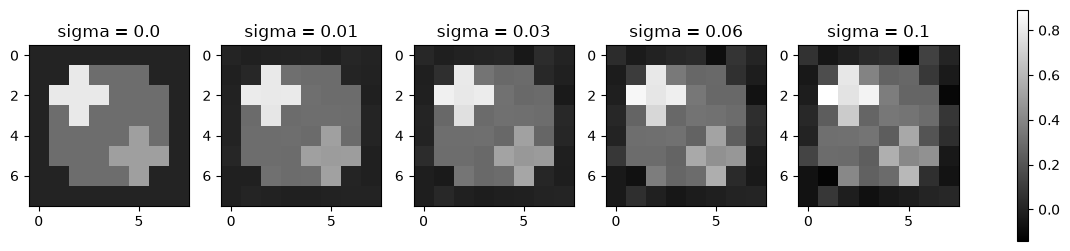

In [9]:
vmin = min(x.min() for x in reconstrucciones.values())
vmax = max(x.max() for x in reconstrucciones.values())

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, sigma in zip(axes, sigmas):
    im = ax.imshow(reconstrucciones[sigma].reshape(n, n), cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(f"sigma = {sigma}")
fig.colorbar(im, ax=axes)
plt.show()

## Inciso c)

**¿Cómo cambia el error al aumentar $\sigma$?**

Crece. Cuanto más ruido tienen las mediciones, más se aleja la reconstrucción del fantoma. Como todo el problema es lineal, el error crece de forma proporcional a $\sigma$.

**¿Por qué el residuo deja de ser nulo?**

Sin ruido, $b_7 = A_7 x_{fantoma}$, así que existe una imagen que reproduce exactamente las mediciones. Con ruido, $b_\sigma$ en general ya no está en $\operatorname{Col}(A_7)$: no hay ninguna imagen $x$ que cumpla $A_7 x = b_\sigma$. Mínimos cuadrados busca la que más se acerca, pero siempre queda una diferencia.

**¿Por qué aparecen valores negativos?**

Porque mínimos cuadrados busca la mejor $x$ entre todos los vectores de $\mathbb{R}^{64}$, sin ninguna condición de que sus componentes sean positivas. En los píxeles donde el fantoma vale 0, el ruido puede empujar el valor reconstruido un poco para abajo y quedar negativo.